# Distance to XX Cygni from time-series photometry

XX Cygni is a high-amplitude δ Scuti variable star. This notebook measures its pulsation period from ~300 CCD images taken over one night with a Celestron EdgeHD 14″ telescope (Sloan r filter), then uses the δ Scuti period–luminosity relation to estimate its distance.

**Pipeline:** flat-field calibration → WCS sky coordinates → aperture photometry of XX Cyg and comparison stars → calibration to catalogue (APASS) magnitudes → Lomb–Scargle period → period–luminosity distance, with uncertainties propagated throughout.

**Result:** period = 0.128 ± 0.048 days (3.08 h); distance = **1.30 ± 0.39 kpc**, consistent with the Gaia DR3 parallax distance of 1.16 ± 0.02 kpc.

*Completed as part of the second-year astrophysics laboratory at the University of Exeter. The raw telescope images are not included in this repository, so the notebook is shown with its saved outputs from the original run.*


In [ ]:
from pathlib import Path

# Folder containing the raw images (WCSXXCygni/), flat fields (flat/) and the
# comparison-star table (xxCyg_ComparisonStars.txt). Not included in this repository.
DATA_DIR = Path('data')

## 1. Data reduction
### 1.1 Loading the images

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path

In [2]:
maindir = DATA_DIR

In [3]:
datafilenames = maindir.joinpath("WCSXXCygni").glob("*.fits")
datafilenames = sorted(datafilenames) # Puts the filenames in a logical order.
print("There are {0} image files in the target data directory".format(len(datafilenames)))
datafilenames[0:10] # List the first 10 filenames.

There are 318 image files in the target data directory


### 1.2 Opening an image

In [4]:
import astropy.io.fits as fits
image = fits.open(datafilenames[100])
image.info()

Filename: data/WCSXXCygni\wcs_CCD_Image_0178.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     154   (1092, 736)   int16 (rescales to uint16)   


In [5]:
image_data = image[0].data

In [6]:
print(image_data.shape)
print(image_data) # Show some of the counts values.

(736, 1092)
[[548 673 588 ... 437 453 395]
 [583 613 550 ... 510 504 437]
 [501 549 514 ... 526 505 470]
 ...
 [431 480 483 ... 462 478 426]
 [442 448 517 ... 456 448 405]
 [447 441 435 ... 403 466 421]]


Text(0.5, 1.0, 'counts')

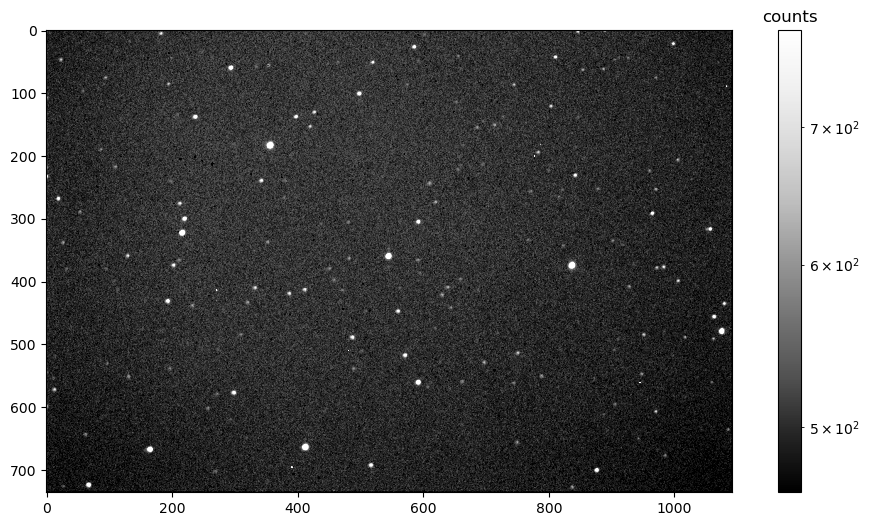

In [7]:
from matplotlib.colors import LogNorm
fig=plt.figure(figsize=(12,6))
uplim=np.percentile(image_data.flatten(),99.9)
downlim=np.percentile(image_data.flatten(),10)
norm = LogNorm(vmin=downlim,vmax=uplim)
ax = plt.subplot()
a=ax.imshow(image_data,cmap='Greys_r',norm=norm)
cb=fig.colorbar(a, ax=ax)
cb.ax.set_title('counts')

In [8]:
import os
maindir.joinpath("raw_images").mkdir(exist_ok=True) # Create directory to hold images
for image_name in datafilenames[:]:
    # print(image_name) # In case you want to see the progress.
    image = fits.open(image_name)
    image_data = image[0].data
    image.close()
    fig, ax = plt.subplots(1, 1, figsize=(10, 6))
    nstd = .2
    vmin = np.nanmedian(image_data)-nstd*np.nanstd(image_data)
    vmax = np.nanmedian(image_data)+nstd*np.nanstd(image_data)
    a = ax.imshow(image_data, cmap='Greys_r', vmin=vmin, vmax=vmax)
    cb = fig.colorbar(a, ax=ax)
    cb.ax.set_title('counts')
    plt.tight_layout()
    _head, _tails = os.path.split(image_name)
    _filename, _ext = os.path.splitext(_tails)
    plt.savefig(maindir.joinpath('raw_images/raw_image_{}.jpg'.format(_filename)))
    plt.close()

### 1.3 Image quality checks

In [9]:
print(len(datafilenames))

318


In [10]:
# Images rejected after visually inspecting every frame: one contains a satellite
# streak (top left of the frame); the rest are very noisy, most likely because of
# passing cloud during the night.
bad_images = ['0087', '0110', '0117', '0119', '0125', '0143', '0144', '0145', '0146',
              '0147', '0148', '0149', '0150', '0177', '0178', '0187', '0240', '0330']
datafilenames = [f for f in datafilenames if f.stem.split('_')[-1] not in bad_images]

In [11]:
print("There are {0} image files in my list of 'good' images.".format(len(datafilenames)))

There are 300 image files in my list of 'good' images.


### 1.4 Image headers (dark and bias already subtracted)

In [12]:
image = fits.open(datafilenames[100])
image_head = image[0].header
image.close()
image_head[:]

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                   16 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 1092                                                  
NAXIS2  =                  736                                                  
DATE-OBS= '2016-10-18T20:47:36' /YYYY-MM-DDThh:mm:ss observation start, UT      
EXPTIME =   30.000000000000000 /Exposure time in seconds                        
EXPOSURE=   30.000000000000000 /Exposure time in seconds                        
XPIXSZ  =   13.600000000000000 /Pixel Width in microns (after binning)          
YPIXSZ  =   13.600000000000000 /Pixel Height in microns (after binning)         
XBINNING=                    2 /Binning factor in width                         
YBINNING=                    2 /Binning factor in height                        
XORGSUBF=                   

In [13]:
print(image_head['HISTORY'])

 Dark subtraction (Simple Auto-dark)
Created by the Astrometry.net suite.
For more details, see http://astrometry.net.
Git URL https://github.com/dstndstn/astrometry.net
Git revision 0.89
Git date Mon_Jan_17_07:47:26_2022_-0500
This is a WCS header was created by Astrometry.net.


### 1.5 Flat-fielding

#### Building a master flat (Sloan r)

In [14]:
list(maindir.joinpath("flat").glob("*.fits"))

In [15]:
flat_files=[]
for x in maindir.joinpath("flat/").glob("*.fits"):
    if x.name.startswith('r'):
        flat_files.append(x)
flat_files = sorted(flat_files)
print('There are {0} Sloan-r-band flatfield images.'.format(len(flat_files)))

There are 5 Sloan-r-band flatfield images.


In [16]:
flat_images=[]
flat_headers=[]
for x in flat_files:
    image = fits.open(x)
    flat_images.append(image[0].data)
    flat_headers.append(image[0].header)
    image.close()

In [17]:
flat_headers[0]

SIMPLE  =                    T                                                  
BITPIX  =                   16 /8 unsigned int, 16 & 32 int, -32 & -64 real     
NAXIS   =                    2 /number of axes                                  
NAXIS1  =                 1092 /fastest changing axis                           
NAXIS2  =                  736 /next to fastest changing axis                   
BSCALE  =   1.0000000000000000 /physical = BZERO + BSCALE*array_value           
BZERO   =   32768.000000000000 /physical = BZERO + BSCALE*array_value           
DATE-OBS= '2016-10-25T17:29:42' /YYYY-MM-DDThh:mm:ss observation start, UT      
EXPTIME =   3.0000000000000000 /Exposure time in seconds                        
EXPOSURE=   3.0000000000000000 /Exposure time in seconds                        
XPIXSZ  =   13.600000000000000 /Pixel Width in microns (after binning)          
YPIXSZ  =   13.600000000000000 /Pixel Height in microns (after binning)         
XBINNING=                   

In [18]:
print('The minimum counts value among all pixels in the whole image is {0}, and the maximum is {1}.'
    .format(np.nanmin(flat_images[0]), np.nanmax(flat_images[0])))
print('The mean, median, and standard deviation are {0}, {1}, and {2}.'
    .format(np.nanmean(flat_images[0]), np.nanmedian(flat_images[0]), np.nanstd(flat_images[0])))

The minimum counts value among all pixels in the whole image is 20220, and the maximum is 50558.
The mean, median, and standard deviation are 22858.835459716913, 22928.0, and 327.9817406868938.


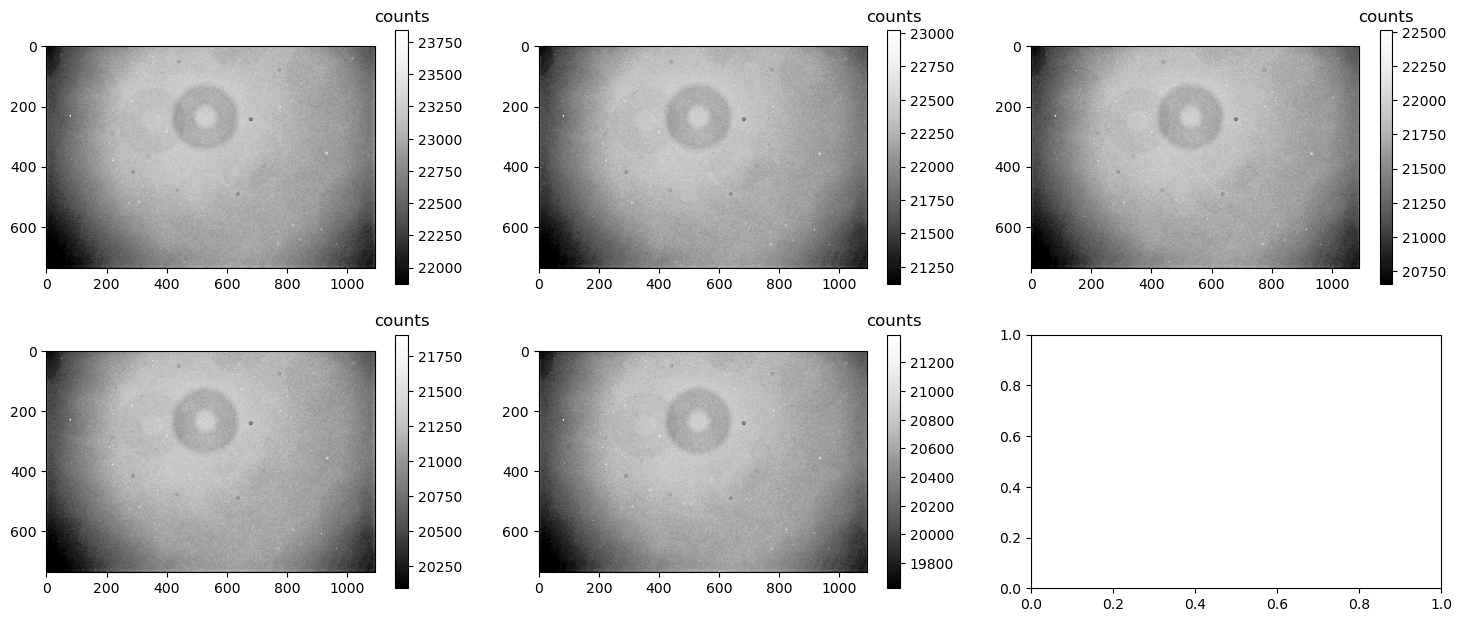

In [19]:
nstd = 3. # This variable is just to specify the range in the image colour scale.
fig, axes = plt.subplots(2, 3, figsize=(6*3,3.625*2))
for i,j in enumerate([(0,0),(0,1),(0,2),(1,0),(1,1)]):
    ax = axes[j]
    vmin = np.nanmean(flat_images[i])-nstd*np.nanstd(flat_images[i])
    vmax = np.nanmean(flat_images[i])+nstd*np.nanstd(flat_images[i])
    a = ax.imshow(flat_images[i], cmap='Greys_r', vmin=vmin, vmax=vmax)
    cb = fig.colorbar(a, ax=ax)
    cb.ax.set_title('counts')

In [20]:
normalised_flats = flat_images[:]
for i,x in enumerate(flat_images):
    normalised_flats[i] = x/(np.nanmedian(x))
    print(np.nanmedian(normalised_flats[i]))

1.0
1.0
1.0
1.0
1.0


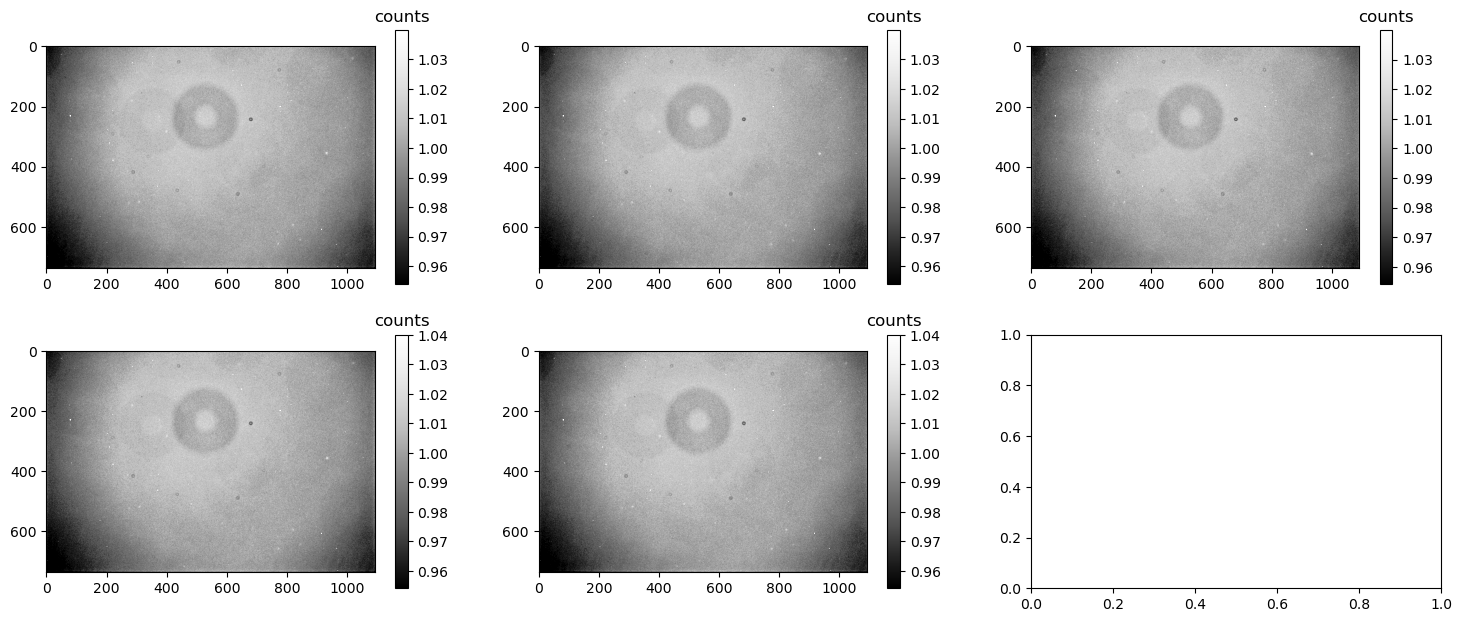

In [21]:
nstd = 3.
fig, axes = plt.subplots(2, 3, figsize=(6*3,3.625*2))
for i,j in enumerate([(0,0),(0,1),(0,2),(1,0),(1,1)]):
    ax = axes[j]
    vmin = np.nanmean(normalised_flats[i])-nstd*np.nanstd(normalised_flats[i])
    vmax = np.nanmean(normalised_flats[i])+nstd*np.nanstd(normalised_flats[i])
    a = ax.imshow(normalised_flats[i], cmap='Greys_r', vmin=vmin, vmax=vmax)
    cb = fig.colorbar(a, ax=ax)
    cb.ax.set_title('counts')

In [22]:
all_norm_flats = np.array(normalised_flats)
print(all_norm_flats.shape)

(5, 736, 1092)


In [23]:
comb_norm_flat = np.median(all_norm_flats, axis=0)
print(comb_norm_flat.shape)

(736, 1092)


In [24]:
print(np.nanmedian(comb_norm_flat))

1.0006467110125647


In [25]:
comb_norm_flat = comb_norm_flat / np.nanmedian(comb_norm_flat)
print(np.nanmedian(comb_norm_flat))

1.0


Text(0.5, 1.0, 'Individual Normalised Flat')

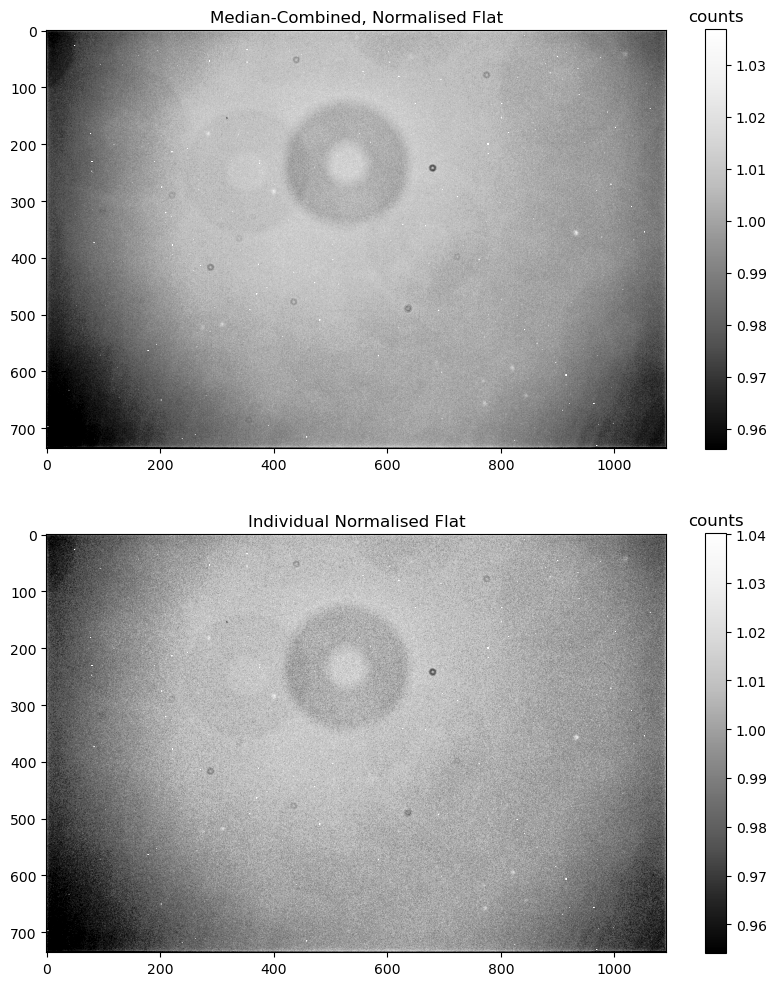

In [26]:
fig, axes = plt.subplots(2, 1, figsize=(10,12))
ax = axes[0]
nstd = 3.
vmin = np.nanmean(comb_norm_flat)-nstd*np.nanstd(comb_norm_flat)
vmax = np.nanmean(comb_norm_flat)+nstd*np.nanstd(comb_norm_flat)
a = ax.imshow(comb_norm_flat, cmap='Greys_r', vmin=vmin, vmax=vmax)
cb = fig.colorbar(a, ax=ax)
cb.ax.set_title('counts')
ax.set_title('Median-Combined, Normalised Flat')
ax = axes[1]
nstd = 3.
nimg = 4
vmin = np.nanmean(normalised_flats[nimg])-nstd*np.nanstd(normalised_flats[nimg])
vmax = np.nanmean(normalised_flats[nimg])+nstd*np.nanstd(normalised_flats[nimg])
a = ax.imshow(normalised_flats[nimg], cmap='Greys_r', vmin=vmin, vmax=vmax)
cb = fig.colorbar(a, ax=ax)
cb.ax.set_title('counts')
ax.set_title('Individual Normalised Flat')

In [27]:
hdu = fits.PrimaryHDU(data=comb_norm_flat)
hdu.header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -64 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 1092                                                  
NAXIS2  =                  736                                                  
EXTEND  =                    T                                                  

In [28]:
maindir.joinpath('working/').mkdir(exist_ok=True) # Create a new directory to store the output file.
new_file_name = 'flat_Sloanr_median_combined.fits' # Give your filenames useful information.
outfile = maindir.joinpath('working/' + new_file_name)
print(outfile)

data/working\flat_Sloanr_median_combined.fits


In [29]:
hdu = fits.PrimaryHDU(comb_norm_flat)
hdu.writeto(outfile, overwrite=True)

#### Applying the flat to the science frames

In [30]:
calibrated_image = image_data / comb_norm_flat

In [31]:
# Just displying image without stretched color scale.
from matplotlib.colors import LogNorm
plt.figure(figsize=(15,8))
uplim=np.percentile(image_data.flatten(),99.9)

<Figure size 1500x800 with 0 Axes>

Text(0.5, 1.0, 'counts')

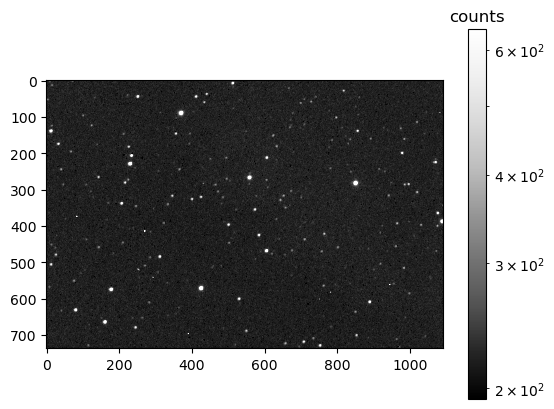

In [32]:
downlim=np.percentile(image_data.flatten(),10)
norm = LogNorm(vmin=downlim,vmax=uplim)
ax = plt.subplot()
a=ax.imshow(calibrated_image,cmap='Greys_r',norm=norm)
cb=fig.colorbar(a, ax=ax)
cb.ax.set_title('counts')

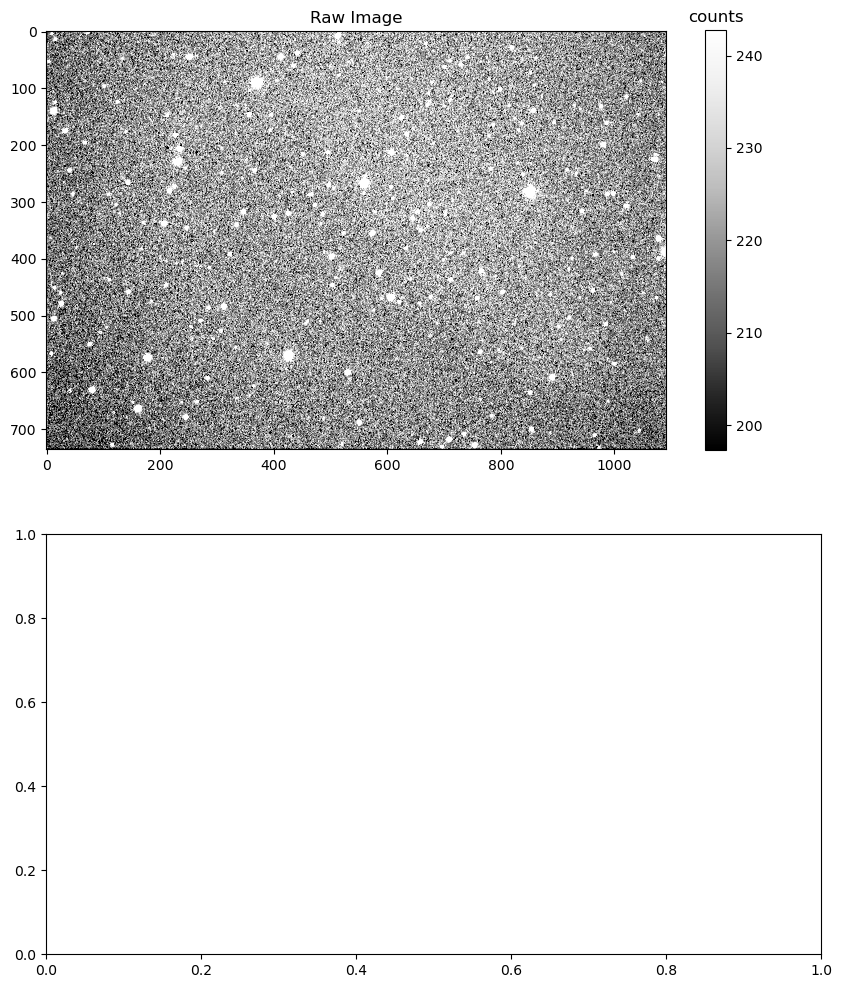

In [33]:
fig, axes = plt.subplots(2, 1, figsize=(10,12))
ax = axes[0]
nstd = .2
vmin = np.nanmedian(image_data)-nstd*np.nanstd(image_data)
vmax = np.nanmedian(image_data)+nstd*np.nanstd(image_data)
a = ax.imshow(image_data, cmap='Greys_r', vmin=vmin, vmax=vmax)
cb = fig.colorbar(a, ax=ax)
cb.ax.set_title('counts')
ax.set_title('Raw Image')
ax = axes[1]
nstd = .2

In [34]:
# vmin = np.nanmedian(calibrated_image)-nstd*np.nanstd(calibrated_image)
# vmax = np.nanmedian(calibrated_image)+nstd*np.nanstd(calibrated_image)
a = ax.imshow(calibrated_image, cmap='Greys_r', vmin=vmin, vmax=vmax)
cb = fig.colorbar(a, ax=ax)
cb.ax.set_title('counts')
ax.set_title('Flatfielded Image')

Text(0.5, 1.0, 'Flatfielded Image')

In [35]:
for image_name in datafilenames[:]:
    #print(image_name) # In case you want to see the progress.
    image = fits.open(image_name)
    image_data = image[0].data
    image_head = image[0].header
    image.close()
    calibrated_image = image_data / comb_norm_flat
    hdu = fits.PrimaryHDU(data=calibrated_image,header=image_head)
    outfile = maindir.joinpath('working/cal_' + image_name.name)
    hdu.writeto(outfile, overwrite=True)

### 1.6 Sky coordinates (WCS)

In [36]:
from astropy.wcs import WCS
import warnings

al_file_name = maindir.joinpath('working/cal_wcs_CCD_Image_0091.fits')
al_image = fits.open(al_file_name)
al_image_data = al_image[0].data
al_image_head = al_image[0].header
al_image.close()
with warnings.catch_warnings():
    # If we didn't suppress this warning, we would get an unrelated message, but
    # don't worry, it doesn't affect the experiment at hand!
    warnings.filterwarnings('ignore', message="'datfix' made the change 'Set MJD-OBS to")
    wcs_info = WCS(al_image_head)
print(wcs_info)

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN-SIP'  'DEC--TAN-SIP'  
CRVAL : 300.881298393  59.0164189707  
CRPIX : 509.222305283  234.891922058  
CD1_1 CD1_2  : -0.000258561111005  -2.95151069953e-05  
CD2_1 CD2_2  : 2.95484389078e-05  -0.000258647289872  
NAXIS : 1092  736


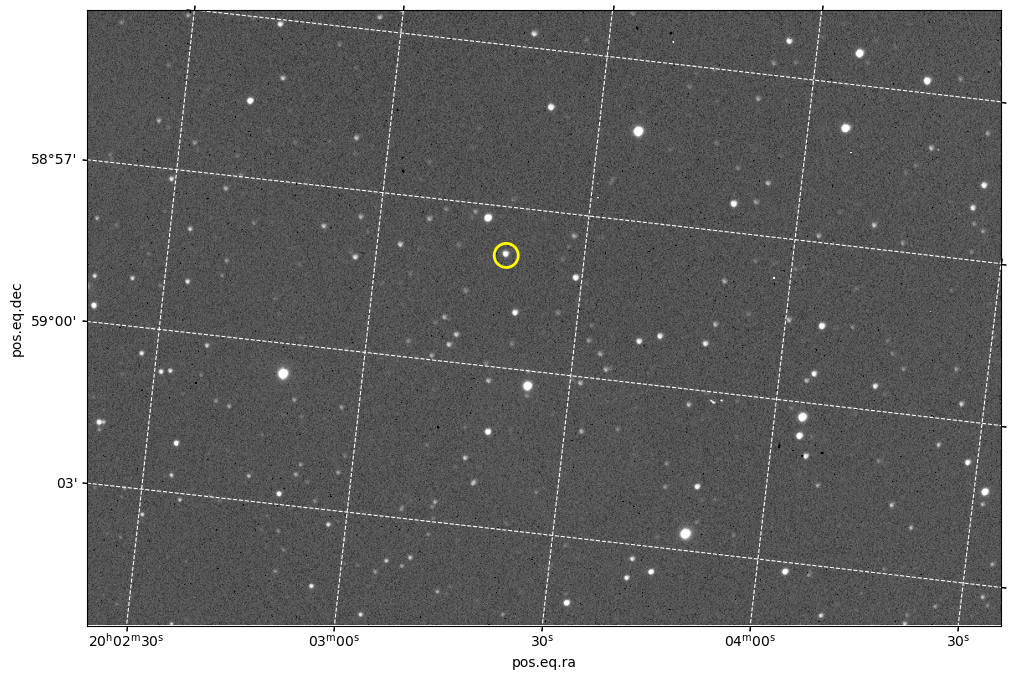

In [42]:
from matplotlib.colors import LogNorm
plt.figure(figsize = (14, 8))
vmin = np.percentile(al_image_data.flatten(),0.1)
vmax = np.percentile(al_image_data.flatten(),99.9)
norm = LogNorm(vmin=vmin, vmax=vmax)
# Here's where we give the WCS info to subplot.
ax = plt.subplot(projection = wcs_info)
ax.imshow(al_image_data, cmap='Greys_r', norm=norm)
# Plot a grid, to show sky coordinate directions.
ax.grid(color='white', ls='dashed',)
ax.invert_xaxis()
# For fun, draw a circle around a set of coordinates (this is NOT XX Cygni).
random_star_ra = (300.8281) # Right ascension coordinate in degrees.
random_star_dec = (58.9651) # Declination coordinate in degrees.
ax.scatter(random_star_ra, random_star_dec, transform=ax.get_transform('fk5'),
    s=300,edgecolor='yellow', facecolor='none',label='Random Star',lw=2)

## 2. Aperture photometry
### 2.1 Choosing comparison stars

In [43]:
import glob
from astropy.table import Table
workingdir = DATA_DIR / 'working'

In [44]:
from astropy.table import Table
starData = Table.read(DATA_DIR / 'xxCyg_ComparisonStars.txt', format='ascii', header_start=8)
# Print the header information for the table.
print(starData.keys())

['StarID', 'RA', 'Dec', 'B_simbad', 'V_simbad', 'Sloan_g', 'gerr', 'Sloan_r', 'r_err', 'Sloan_i', 'i_err']


In [45]:
print(starData[0:6])

     StarID             RA               Dec         ... r_err Sloan_i i_err
--------------- ----------------- ------------------ ... ----- ------- -----
         XX Cyg 300.8151983749999  58.95458783308665 ... 0.136  11.433 0.194
GSC 03948-02563       300.8280875  58.96506111145021 ... 0.006  13.003 0.014
TYC 3948-2105-1 300.8503416666667  59.00529166645474 ... 0.005  10.508 0.008
    BD+58  2037 300.7029583333334 59.009939444859825 ...  -0.0   9.627  -0.0
    BD+58  2043         300.95501  59.04530499988131 ...  -0.0   9.659  -0.0
TYC 3948-2018-1 301.0171500000001  59.00512777752346 ... 0.038  10.767 0.012


In [46]:
print(starData[np.argsort(starData['Sloan_r'])][0:6])

     StarID             RA                Dec         ... r_err Sloan_i i_err
--------------- ------------------ ------------------ ... ----- ------- -----
      HD 190961  301.0995074583334  58.83460347228579 ...  -0.0   9.026  -0.0
    BD+58  2035  300.6276933333333  58.88632027784984 ...  -0.0   9.547  -0.0
    BD+58  2043          300.95501  59.04530499988131 ...  -0.0   9.659  -0.0
    BD+58  2037  300.7029583333334 59.009939444859825 ...  -0.0   9.627  -0.0
    BD+58  2048 301.21176249999996 58.921469999949146 ... 0.041  10.385 0.082
TYC 3948-2542-1 300.89915333333335 58.922608333163794 ... 0.024  10.307 0.043


In [47]:
print('The Sloan r magnitude of "{0}" is {1}.'
    .format(starData[2]['StarID'], starData[2]['Sloan_r']))

The Sloan r magnitude of "TYC 3948-2105-1" is 10.886.


In [48]:
al_files = workingdir.glob('cal_wcs_*.fits')
al_files = sorted(al_files) # Not necessary, but orders filenames.

print('There are {0} aligned, calibrated image files: '.format(len(al_files)))
al_files[0:5]

There are 318 aligned, calibrated image files: 


In [49]:
from astropy.wcs import WCS
import warnings
al_image = fits.open(al_files[12])
al_image_data = al_image[0].data
al_image_head = al_image[0].header
with warnings.catch_warnings():
# Remember this just filters out a warning.
    warnings.filterwarnings('ignore', message="'datfix' made the change 'Set MJD-OBS to")
    wcs_info = WCS(al_image_head)
al_image.close()

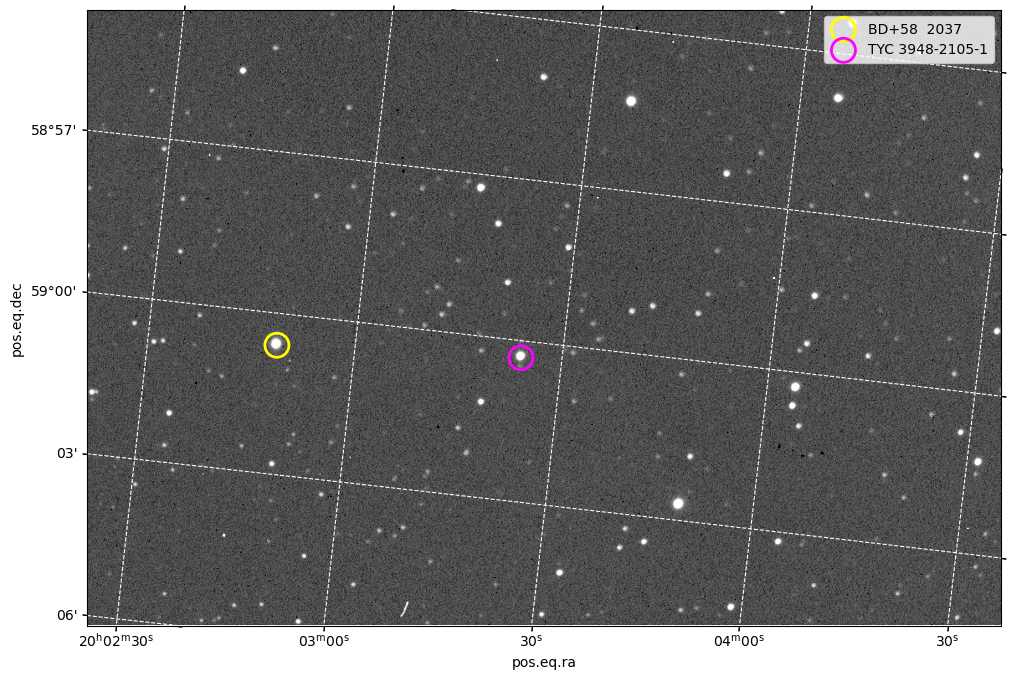

In [50]:
from matplotlib.colors import LogNorm

plt.figure(figsize = (14, 8))

vmin = np.percentile(al_image_data.flatten(),0.1)
vmax = np.percentile(al_image_data.flatten(),99.9)
norm = LogNorm(vmin=vmin, vmax=vmax)

ax = plt.subplot(projection = wcs_info)
ax.imshow(al_image_data, cmap='Greys_r', norm=norm)

ax.grid(color='white', ls='dashed',)
ax.invert_xaxis()

# Draw a circle around some stars, just to identify them.

calstarData = starData[3] # 4th star in table
ax.scatter(calstarData['RA'], calstarData['Dec'], transform=ax.get_transform('fk5'), s=300,
    edgecolor='yellow', facecolor='none',label=calstarData['StarID'],lw=2)
calstarData = starData[2] # 3rd star in table
ax.scatter(calstarData['RA'], calstarData['Dec'], transform=ax.get_transform('fk5'), s=300,
    edgecolor='magenta',facecolor='none',label=calstarData['StarID'],lw=2)

ax.legend()

In [51]:
targetData = starData[[0,1,2,3,4,5,6,7,8,9]]

Text(300.7129583333334, 59.01993944485982, 'BD+58  2037')

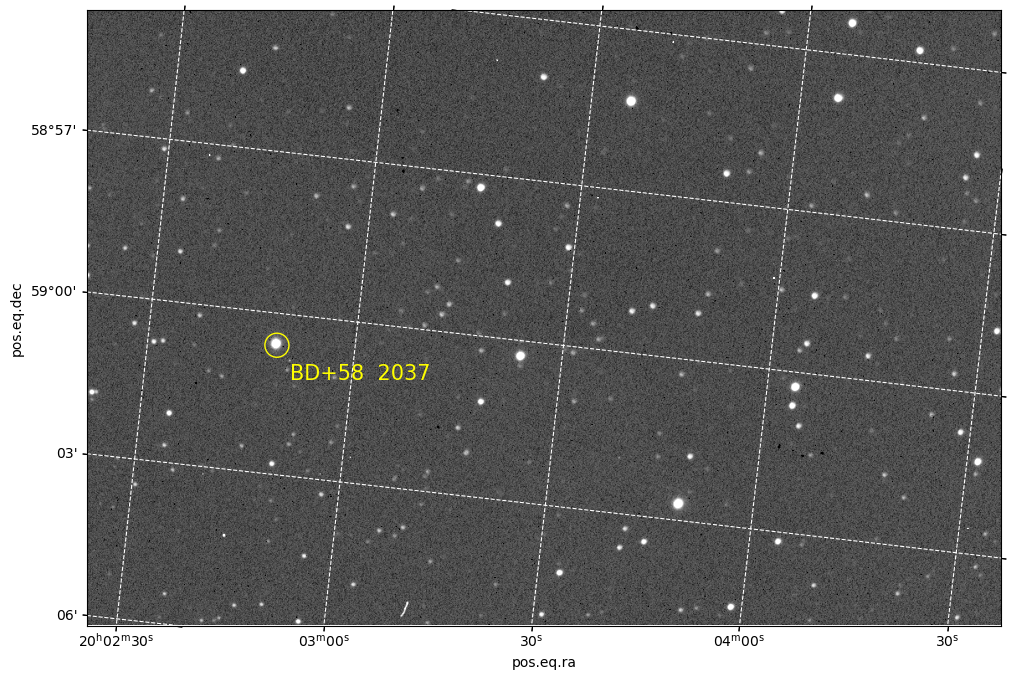

In [52]:
from matplotlib.colors import LogNorm
plt.figure(figsize = (14, 8))
vmin = np.percentile(al_image_data.flatten(),0.1)
vmax = np.percentile(al_image_data.flatten(),99.9)
norm = LogNorm(vmin=vmin, vmax=vmax)
ax = plt.subplot(projection = wcs_info)
ax.imshow(al_image_data, cmap='Greys_r', norm=norm)
ax.grid(color='white', ls='dashed',)
ax.invert_xaxis()
# Draw a circle around a calibrator star, just to identify it.
calstarData = starData[3]
# calstarData = starData[8]
# 0 - out of frame
# 1 - edge of frame
# 2 - near edge, out in some frames
# 3 - good
# 4 - out of frame
# 5 - good
# 6 - good
# 7 - good
# 8 - near edge, might be ok
# 9 - out of frame
# 10 - XX Cyg
# 11 - edge of frame
# 12 - edge of frame
# 13 - edge of frame
# 14 - edge of frame
# 15 - edge of frame
# 16 - out of frame
# 17 - edge of frame
# 18 - good but faint
# So use 3, 5, 6, 7, and maybe 8
ax.scatter(calstarData['RA'], calstarData['Dec'], transform=ax.get_transform('fk5'), s=300,
edgecolor='yellow', facecolor='none',label='Calibrator Star')
offset=.01
plt.annotate(calstarData['StarID'],[calstarData['RA']+offset,calstarData['Dec']+offset],
xycoords=ax.get_transform('fk5'),color='yellow',size=15)

In [53]:
# Make table holding only the "good" calibrators, and XX Cyg which is the 0th entry.
targetData = starData[[0, 1, 2, 5, 6]]
print(targetData)

     StarID             RA                Dec         ... r_err Sloan_i i_err
--------------- ------------------ ------------------ ... ----- ------- -----
         XX Cyg  300.8151983749999  58.95458783308665 ... 0.136  11.433 0.194
GSC 03948-02563        300.8280875  58.96506111145021 ... 0.006  13.003 0.014
TYC 3948-2105-1  300.8503416666667  59.00529166645474 ... 0.005  10.508 0.008
TYC 3948-2018-1  301.0171500000001  59.00512777752346 ... 0.038  10.767 0.012
TYC 3948-2542-1 300.89915333333335 58.922608333163794 ... 0.024  10.307 0.043


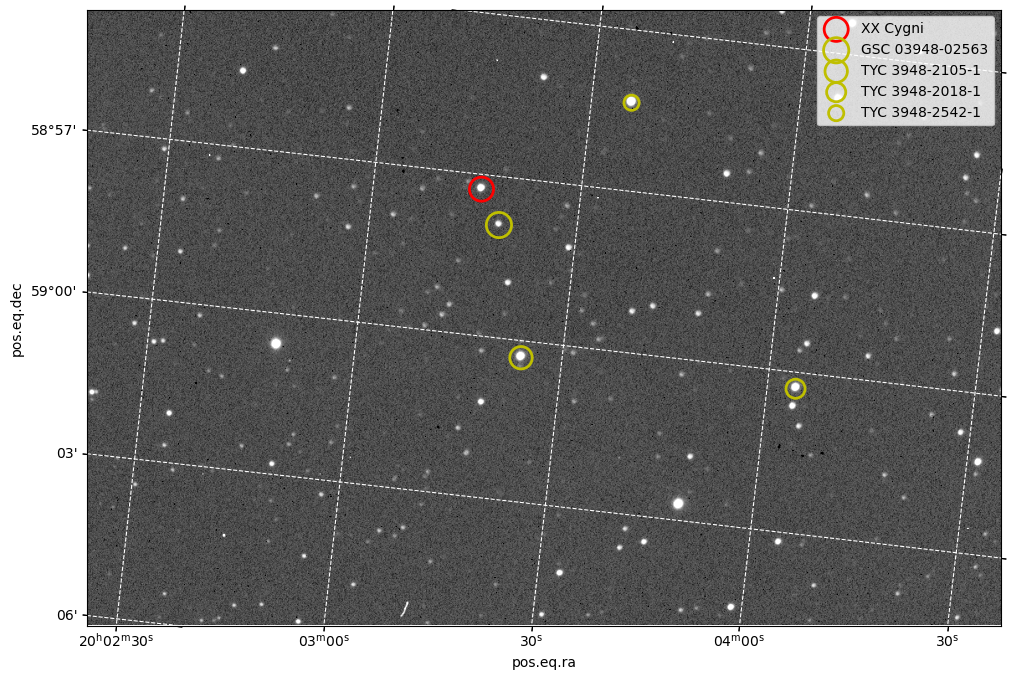

In [54]:
# Plot the postions of all targets
from matplotlib.colors import LogNorm
plt.figure(figsize = (14, 8))
vmin = np.percentile(al_image_data.flatten(),0.1)
vmax = np.percentile(al_image_data.flatten(),99.9)
norm = LogNorm(vmin=vmin, vmax=vmax)
ax = plt.subplot(projection = wcs_info)
ax.imshow(al_image_data, cmap='Greys_r', norm=norm)
ax.grid(color='white', ls='dashed',)
ax.invert_xaxis()
# cols = ['y','b','g','m','r']
# Because XX Cyg is the first entry in targetData and starData
ax.scatter(starData[0]['RA'], starData[0]['Dec'], transform=ax.get_transform('fk5'), s=300,
    edgecolor='r', facecolor='none',label='XX Cygni',lw=2)
for i in range(1, len(targetData)):
    ax.scatter(targetData[i]['RA'], targetData[i]['Dec'], transform=ax.get_transform('fk5'), s=400-70*i,
    edgecolor='y', facecolor='none',label=targetData[i]['StarID'],lw=2)
ax.legend()

### 2.2 Defining apertures

In [55]:
import photutils
from astropy import units as u
from astropy.coordinates import SkyCoord

In [56]:
targetCoords = SkyCoord(targetData['RA'], targetData['Dec'], unit = 'deg')
print(targetCoords[0])

<SkyCoord (ICRS): (ra, dec) in deg
    (300.81519837, 58.95458783)>


In [57]:
targetApRad = 12.0*u.arcsec # Radius of the stellar aperture.
skyAnR1 = 15.0*u.arcsec # Inner radius of the sky annulus.
skyAnR2 = 25.0*u.arcsec # Outer radius of the sky annulus.
targetApertures = photutils.aperture.SkyCircularAperture(targetCoords, r = targetApRad)
skyApertures = photutils.aperture.SkyCircularAnnulus(targetCoords, r_in=skyAnR1,
r_out=skyAnR2)
print(targetApertures[0:2])
# print(skyApertures)

Aperture: SkyCircularAperture
positions: <SkyCoord (ICRS): (ra, dec) in deg
    [(300.81519837, 58.95458783), (300.8280875 , 58.96506111)]>
r: 12.0 arcsec


In [58]:
targetApertures = targetApertures.to_pixel(wcs_info)
skyApertures = skyApertures.to_pixel(wcs_info)
print(targetApertures[0:2])
print('Area of star apertures in pixels = {}'.format(targetApertures.area))
print('Area of sky apertures in pixels = {}'.format(skyApertures.area))

Aperture: CircularAperture
positions: [[620.11378818, 520.83012518],
            [599.27536455, 477.96057654]]
r: 12.809244512102916
Area of star apertures in pixels = 515.4622966253128
Area of sky apertures in pixels = 1431.8397128480915


(247.34733960358614, 317.34733960358614)

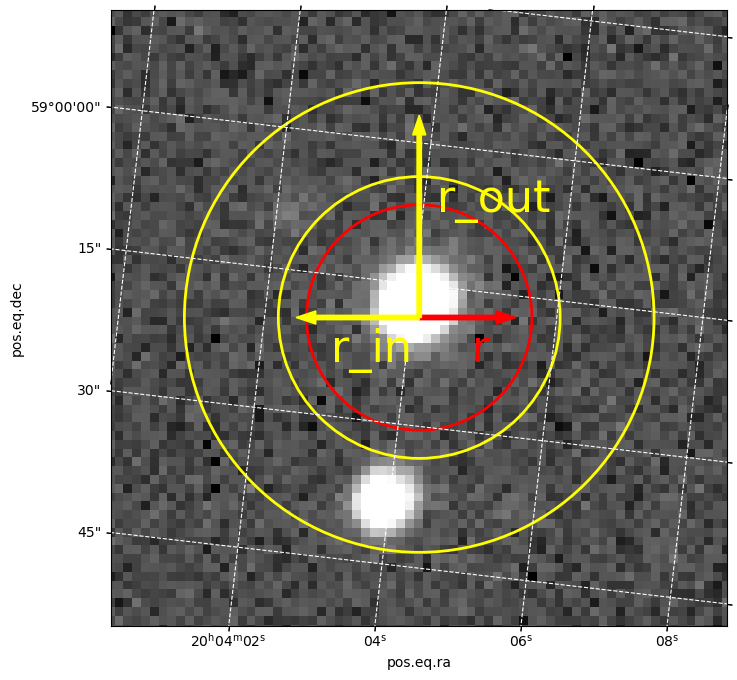

In [59]:
plt.figure(figsize=(8,8))

vmin = np.percentile(al_image_data.flatten(),0.1)
vmax = np.percentile(al_image_data.flatten(),99.9)
norm = LogNorm(vmin=vmin, vmax=vmax)

ax = plt.subplot(projection=wcs_info)

ax.imshow(al_image_data, cmap='Greys_r', norm=norm)
ax.grid(color='white', ls='dashed', )
ax.invert_xaxis()
nstr = 3 # just to specify which star to plot

# Define the x, y positions for cleaner code

xpos = targetApertures[nstr].positions[0]
ypos = targetApertures[nstr].positions[1]

# Draw the apertures on the plot.

targetApertures[nstr].plot(color = 'red', lw=2)
skyApertures[nstr].plot(color = 'yellow', lw=2)

# Annotate the plot with arrows and text.

ax.arrow(xpos, ypos, -11,0,color='red' ,width=0.5,length_includes_head=True,zorder=20)
ax.arrow(xpos, ypos, 14,0,color='yellow' ,width=0.5,length_includes_head=True,zorder=20)
ax.arrow(xpos, ypos, 0,23,color='yellow' ,width=0.5,length_includes_head=True,zorder=20)

ax.text(xpos-6,ypos-5,'r',color='red',fontsize=32)
ax.text(xpos+10,ypos-5,'r_in',color='yellow',fontsize=32)
ax.text(xpos-2,ypos+12,'r_out',color='yellow',fontsize=32)
# Zoom in near plotted star.
npix = 35 # Sets 1/2 of zoom box size in pixels.
ax.set_xlim(xpos+npix, xpos-npix)
ax.set_ylim(ypos-npix, ypos+npix)
# plt.savefig('test.pdf') # Uncomment to save image as pdf.

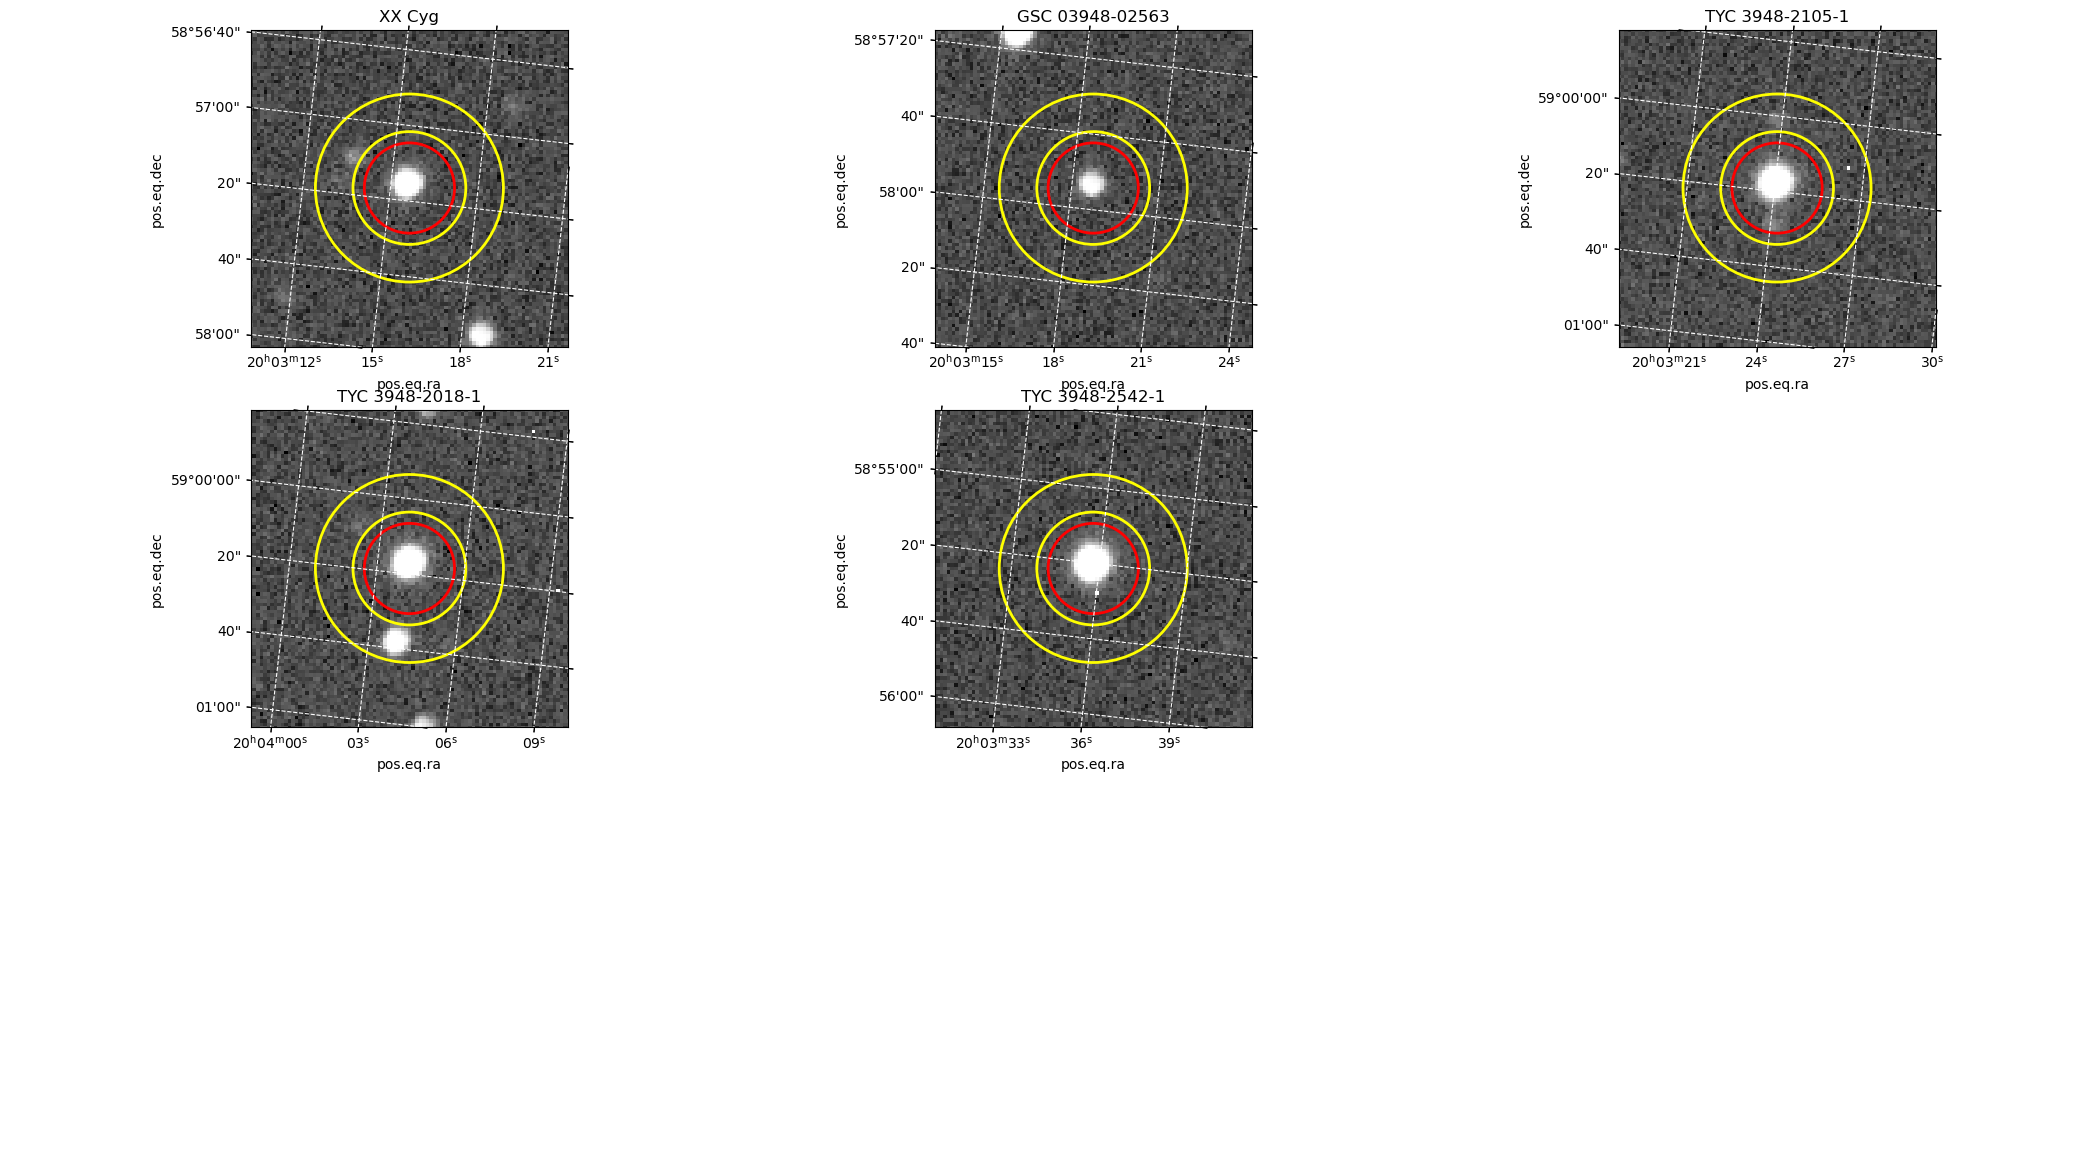

In [60]:
# We are making a 3x3 grid of plots, so we need to make a 3x3 grid of axes.
# If you have more or fewer stars, you may need to change the size of the figure grid.
fig, axes = plt.subplots(3, 3, figsize=(25, 14), subplot_kw={'projection': wcs_info})
vmin = np.percentile(al_image_data.flatten(), 0.1)
vmax = np.percentile(al_image_data.flatten(), 99.9)
norm = LogNorm(vmin=vmin, vmax=vmax)
for i, ax in enumerate(axes.flat):
    # Remove any unused axes subplots from the output figure once we run out of
    # stars to plot.
    if i >= len(targetData):
        ax.cla()
        continue
    ax.imshow(al_image_data, cmap='Greys_r', norm=norm)
    ax.grid(color='white', ls='dashed', )
    ax.invert_xaxis()
    # Define the x, y positions for cleaner code
    xpos = targetApertures[i].positions[0]
    ypos = targetApertures[i].positions[1]
    # Draw the apertures on the plot.
    targetApertures[i].plot(color='red', lw=2, ax=ax)
    skyApertures[i].plot(color='yellow', lw=2, ax=ax)
    ax.set_title(targetData[i]['StarID'])
    # Zoom in near plotted star.
    npix = 45 # Sets 1/2 of zoom box size in pixels.
    ax.set_xlim(xpos+npix, xpos-npix)
    ax.set_ylim(ypos-npix, ypos+npix)

### 2.3 Summing counts in each aperture

In [61]:
# Make a list of apertures for photutils, which can work on multiple apertures at once.
bothApertures = [targetApertures, skyApertures]
phot_table = photutils.aperture.aperture_photometry(al_image_data, bothApertures,
wcs=wcs_info)
print(phot_table[0:2])


 id      xcenter           ycenter        aperture_sum_0    aperture_sum_1 
           pix               pix                                           
--- ----------------- ----------------- ------------------ ----------------
  1 620.1137881825254 520.8301251797409  190981.9009451216 305466.848812906
  2 599.2753645490362 477.9605765415517 132091.69880256173 301816.993230054


### 2.4 Sky subtraction

In [62]:
skyPerPixel = phot_table['aperture_sum_1'] / skyApertures.area
skyPerTargetAperture = skyPerPixel * targetApertures.area
# Add a new column to the table for the sky-subtracted target counts.
phot_table['Target_Counts'] = phot_table['aperture_sum_0'] - skyPerTargetAperture
print(phot_table[0:2])

 id      xcenter           ycenter      ...  aperture_sum_1    Target_Counts   
           pix               pix        ...                                    
--- ----------------- ----------------- ... ---------------- ------------------
  1 620.1137881825254 520.8301251797409 ... 305466.848812906  81013.83537247547
  2 599.2753645490362 477.9605765415517 ... 301816.993230054 23437.581239742343


### 2.5 Counts to flux

In [63]:
# Get the exposure time from the image header
expTime = float(al_image_head['EXPTIME'])
print('Exposure time = {} seconds.'.format(expTime))
flux_uncalibrated = phot_table['Target_Counts'] / expTime

Exposure time = 30.0 seconds.


### 2.6 Flux to instrumental magnitude

In [64]:
mag_uncalibrated = -2.5 * np.log10(flux_uncalibrated)
# Add a new column to the table for the Sloan r magnitude.
phot_table['rMag_Inst'] = mag_uncalibrated
print(phot_table[0:2])

 id      xcenter      ...   Target_Counts         rMag_Inst     
           pix        ...                                       
--- ----------------- ... ------------------ -------------------
  1 620.1137881825254 ...  81013.83537247547  -8.578594845978385
  2 599.2753645490362 ... 23437.581239742343 -7.2319788392841335


### 2.7 Photometry for every frame

In [85]:
obsDate = [] # To hold the time of each observation.
rMag_xxCyg_inst = [] # To hold the magnitudes of XX Cyg.
rMag_cals_inst = [] # To old mags of calibrators.

for i, x in enumerate(al_files[:]):
    
    # Open file, extract image data and header.
    
    al_image = fits.open(x)
    al_image_data = al_image[0].data
    al_image_head = al_image[0].header
    # Just in case we don't have a WCS solution in the header!
    if 'WCSSOLVE' not in [key for key in al_image_head.keys()]:
        continue
    with warnings.catch_warnings():
        # Remember this just filters out a warning.
        warnings.filterwarnings('ignore', message="'datfix' made the change 'Set MJD-OBS to")
        wcs_info = WCS(al_image_head)
    al_image.close()
    
    # Extract the date/time of observation.
  
    obsDate.append(float(al_image_head['JD-HELIO']))
   
    # Perform aperture photometry (following steps above).
   
    targetApertures = photutils.aperture.SkyCircularAperture(targetCoords, r=targetApRad)
    skyApertures = photutils.aperture.SkyCircularAnnulus(targetCoords, r_in=skyAnR1, r_out=skyAnR2)
    
    targetApertures = targetApertures.to_pixel(wcs_info)
    skyApertures = skyApertures.to_pixel(wcs_info)
    bothApertures = [targetApertures, skyApertures]
    
    phot_table = photutils.aperture.aperture_photometry(al_image_data, bothApertures,wcs=wcs_info)
    
    skyPerPixel = phot_table['aperture_sum_1'] / skyApertures.area
    skyPerTargetAp = skyPerPixel * targetApertures.area
    
    targetCounts = phot_table['aperture_sum_0'] - skyPerTargetAp
    expTime = float(al_image_head['EXPTIME'])
    flux_uncalibrated = targetCounts / expTime
    mag_uncalibrated = -2.5 * np.log10(flux_uncalibrated)
    offset_err = np.sqrt(np.sum(np.square(rMag_cals_inst_err))) / np.sqrt(np.count_nonzero(rMag_cals_inst_err) - 1)
    xxCyg_app_err = np.sqrt(np.square(rMag_xxCyg_inst_err) + np.square(offset_err))
    cals_app_err = np.sqrt(np.square(rMag_cals_inst_err) + np.square(offset_err))
    phot_table['rMag_Inst'] = mag_uncalibrated
    
    # Save the magnitude data to our lists.
    
    ixxc = np.where(targetData['StarID']=='XX Cyg')[0]
    ical = np.where(targetData['StarID']!='XX Cyg')[0]
    rMag_xxCyg_inst.append(float(phot_table['rMag_Inst'][ixxc][0]))
    rMag_cals_inst.append(phot_table['rMag_Inst'][ical])
    
    # You might want to print out some progress information,
    # in case you need to identify which images cause problems.
    #print(i)

obsDate = np.array(obsDate)
rMag_xxCyg_inst = np.array(rMag_xxCyg_inst)
rMag_cals_inst = np.array(rMag_cals_inst)

In [86]:
print('First 3 image times =', obsDate[0:3])
print('First 3 inst. mags of XX Cygni =', rMag_xxCyg_inst[0:3])
print('First 3 inst. mags of calibrator 1 = ',
rMag_cals_inst[0:3,0])
print('First 3 inst. mags of calibrator 2 = ',
rMag_cals_inst[0:3,1])

First 3 image times = [2457680.29147387 2457680.30104546 2457680.30146212]
First 3 inst. mags of XX Cygni = [-8.60971481 -8.52647865 -8.5262122 ]
First 3 inst. mags of calibrator 1 =  [-7.13756993 -7.15431443 -7.2052278 ]
First 3 inst. mags of calibrator 2 =  [-9.62577283 -9.6358199  -9.64229211]


In [88]:
print('HJD =',obsDate[10],'days')

HJD = 2457680.304668086 days


(-712.7166521353181, -712.5378799327184)

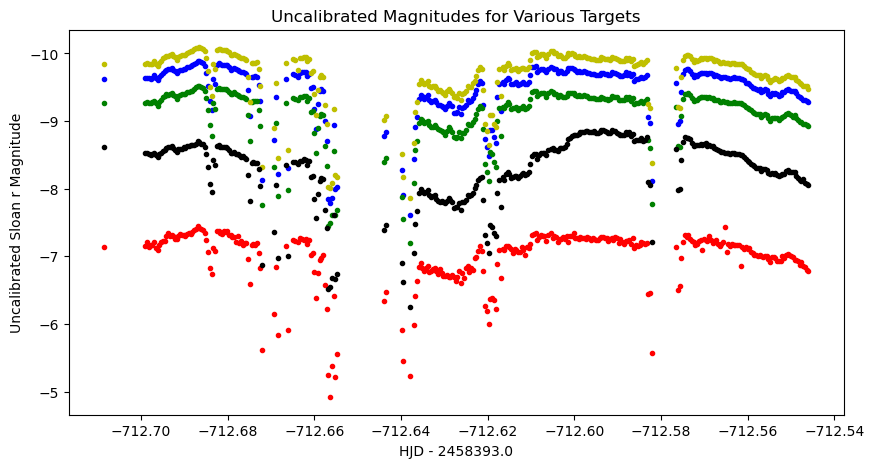

In [89]:
plt.figure(figsize=(10,5))
ax = plt.subplot()
offset = 2458393. # HJD to subtract for display purposes
plt.plot(obsDate-offset, rMag_cals_inst[:,0],'r.')
plt.plot(obsDate-offset, rMag_cals_inst[:,1],'b.')
plt.plot(obsDate-offset, rMag_cals_inst[:,2],'g.')
plt.plot(obsDate-offset, rMag_cals_inst[:,3],'y.')
plt.plot(obsDate-offset, rMag_xxCyg_inst,'k.')
plt.title('Uncalibrated Magnitudes for Various Targets')
plt.xlabel('HJD - '+str(offset))
plt.ylabel('Uncalibrated Sloan r Magnitude')
ax.invert_yaxis() # Small mag = bright star
ax.set_xlim() # Show subset of data.

## 3. Magnitude calibration

### 3.1 Calibration at a single time

In [90]:
print(targetData[1:3])

     StarID             RA               Dec        ... r_err Sloan_i i_err
--------------- ----------------- ----------------- ... ----- ------- -----
GSC 03948-02563       300.8280875 58.96506111145021 ... 0.006  13.003 0.014
TYC 3948-2105-1 300.8503416666667 59.00529166645474 ... 0.005  10.508 0.008


In [91]:
#compute mean of all calibrators within an image
delta_rMag = targetData['Sloan_r'][1:] - rMag_cals_inst[10]
#compute mean over all images
rMagOffset = np.nanmean(delta_rMag)
print('The average literature - uncalibrated magnitude offset is',rMagOffset)

The average literature - uncalibrated magnitude offset is 20.47062571545583


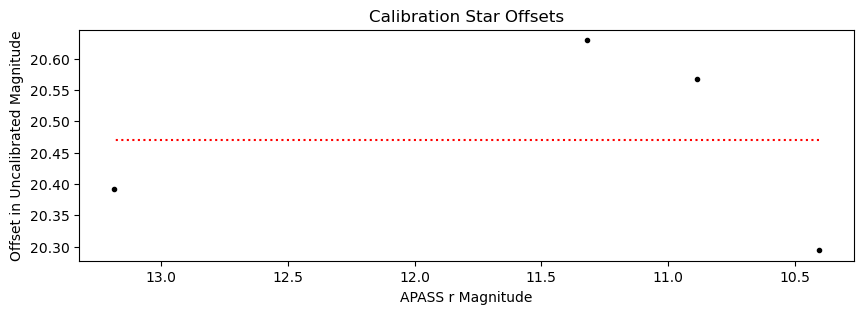

In [92]:
plt.figure(figsize=(10,3))
ax = plt.subplot()
plt.plot(targetData['Sloan_r'][1:], delta_rMag, 'k.')
# Plot a line showing the average value.
xrange = [np.nanmin(targetData['Sloan_r']), np.nanmax(targetData['Sloan_r'])]
plt.plot(xrange,[rMagOffset,rMagOffset],'r:')
plt.xlabel('APASS r Magnitude')
plt.ylabel('Offset in Uncalibrated Magnitude')
plt.title('Calibration Star Offsets')
ax.invert_xaxis() # Small mag = bright star

### 3.2 Calibrating every frame

In [93]:
# rMag_cals = rMag_cals_inst[:,:]
# rMag_xxCyg = rMag_xxCyg_inst[:]
rMag_cals = np.copy(rMag_cals_inst)
rMag_xxCyg = np.copy(rMag_xxCyg_inst)

magOffsetStd = []

for i in range(len(rMag_cals_inst)):
    delta_rMag = targetData['Sloan_r'][1:] - rMag_cals_inst[i,:]
    # print(delta_rMag)
    magOffset = np.nanmean(delta_rMag)
    magOffsetStd.append(np.nanstd(delta_rMag))
    rMag_cals[i,:] = rMag_cals_inst[i,:] + magOffset
    rMag_xxCyg[i] = rMag_xxCyg[i] + magOffset
magOffsetStd = np.array(magOffsetStd)
magOffsetAvg = np.mean(magOffsetStd)
print('Average of std of offset of all calibrators =',magOffsetAvg)
# Compute the standard deviations about the mean.
erMag_cals = []
for i in range(len(targetData['Sloan_r'][1:])):
    erMag_cals.append(np.nanstd(rMag_cals[:,i]))
erMag_cals = np.array(erMag_cals)
print('Standard deviation for each calibrator star =',erMag_cals)
# print(np.arange(5))
erMag_sum = np.sqrt(np.nansum(erMag_cals**2.))
print('Quadrature sum of std of all calibrators =',erMag_sum)
# magOffsetStd
# rMag_cals[0:5]

Average of std of offset of all calibrators = 0.13507355659893214
Standard deviation for each calibrator star = [0.03779912 0.01343067 0.01657904 0.01480397]
Quadrature sum of std of all calibrators = 0.04586042567542333


(-712.7166521353181, -712.5378799327184)

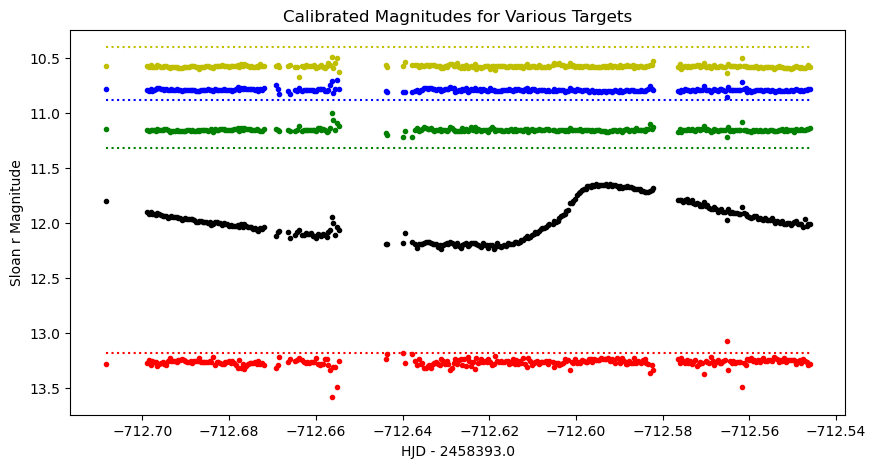

In [94]:
plt.figure(figsize=(10,5))
ax = plt.subplot()
offset = 2458393.
xrange = [np.nanmin(obsDate)-offset,np.nanmax(obsDate)-offset]
ndates = len(obsDate)
plt.plot(obsDate-offset, rMag_cals[:,0],'r.')
plt.plot(xrange,[targetData['Sloan_r'][1],targetData['Sloan_r'][1]],'r:')
plt.plot(obsDate-offset, rMag_cals[:,1],'b.')
plt.plot(xrange,[targetData['Sloan_r'][2],targetData['Sloan_r'][2]],'b:')
plt.plot(obsDate-offset, rMag_cals[:,2],'g.')
plt.plot(xrange,[targetData['Sloan_r'][3],targetData['Sloan_r'][3]],'g:')
plt.plot(obsDate-offset, rMag_cals[:,3],'y.')
plt.plot(xrange,[targetData['Sloan_r'][4],targetData['Sloan_r'][4]],'y:')
# plt.plot(obsDate-offset, rMag_cals[:,4],'m.')
plt.plot(obsDate-offset, rMag_xxCyg,'k.')
# xrange = [np.nanmin(targetData['Sloan_r']), np.nanmax(targetData['Sloan_r'])]
# plt.plot(xrange,[offset,offset],'r:')
plt.title('Calibrated Magnitudes for Various Targets')
plt.xlabel('HJD - '+str(offset))
plt.ylabel('Sloan r Magnitude')
#
ax.invert_yaxis() # Small mag = bright star
ax.set_xlim()

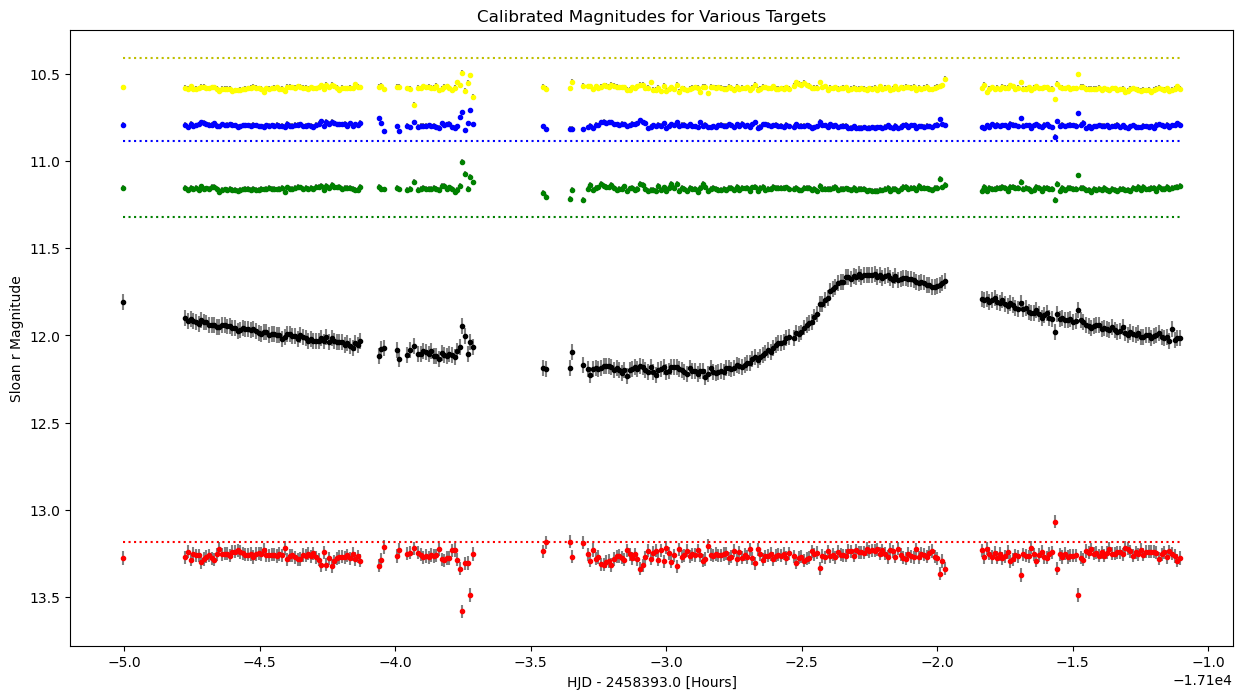

In [95]:
plt.figure(figsize=(15,8))
ax = plt.subplot()
offset = 2458393.
ndates = len(obsDate)
xval = (obsDate-offset)*24.
xrange = [np.nanmin(xval),np.nanmax(xval)]
plt.errorbar(xval, rMag_cals[:,0],np.repeat(erMag_cals[0],ndates),marker='.',mfc='red',mec='red',c='grey',ls='None')
plt.plot(xrange,[targetData['Sloan_r'][1],targetData['Sloan_r'][1]],'r:')
plt.errorbar(xval, rMag_cals[:,1],np.repeat(erMag_cals[1],ndates), marker='.',mfc='blue', mec='blue',c='grey',ls='None')
plt.plot(xrange,[targetData['Sloan_r'][2],targetData['Sloan_r'][2]],'b:')
plt.errorbar(xval, rMag_cals[:,2],np.repeat(erMag_cals[2],ndates), marker='.',mfc='green', mec='green',c='grey',ls='None')
plt.plot(xrange,[targetData['Sloan_r'][3],targetData['Sloan_r'][3]],'g:')
plt.errorbar(xval, rMag_cals[:,3],np.repeat(erMag_cals[3],ndates), marker='.',mfc='yellow', mec='yellow',c='grey',ls='None')
plt.plot(xrange,[targetData['Sloan_r'][4],targetData['Sloan_r'][4]],'y:')
plt.errorbar(xval, rMag_xxCyg,np.repeat(erMag_sum,ndates),marker='.',mfc='black',mec='black',c='grey',ls='None')
plt.title('Calibrated Magnitudes for Various Targets')
plt.xlabel('HJD - '+str(offset)+' [Hours]')
plt.ylabel('Sloan r Magnitude')
#
ax.invert_yaxis() # Small mag = bright star

## 4. Pulsation period (Lomb–Scargle periodogram)
The time series is unevenly sampled, so a Lomb–Scargle periodogram is used to find the dominant period, and the light curve is folded on it.


Best period = 0.1283 days


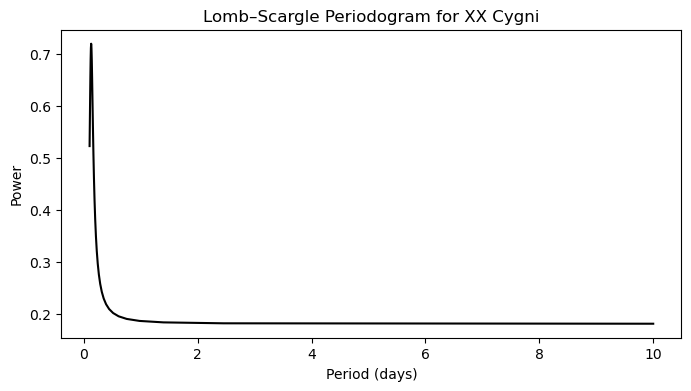

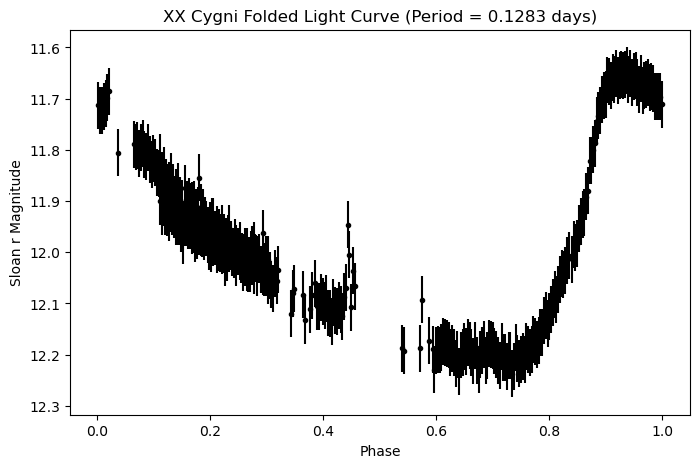

In [96]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle

# Light curve of XX Cyg from the calibration step above
time = xval / 24.0                     # Convert hours back to days
mag = rMag_xxCyg
mag_err = erMag_sum

# --- Compute the Lomb–Scargle periodogram ---
frequency, power = LombScargle(time, mag, mag_err).autopower(
    minimum_frequency=0.1,             # lower limit (cycles per day)
    maximum_frequency=10,              # upper limit (cycles per day)
    samples_per_peak=20
)

# --- Find best frequency and period ---
best_frequency = frequency[np.argmax(power)]
best_period = 1 / best_frequency

print(f"Best period = {best_period:.4f} days")

# --- Plot the periodogram ---
plt.figure(figsize=(8,4))
plt.plot(1/frequency, power, 'k-')
plt.xlabel("Period (days)")
plt.ylabel("Power")
plt.title("Lomb–Scargle Periodogram for XX Cygni")
plt.show()

# --- Fold the light curve by the best period ---
phase = (time % best_period) / best_period

plt.figure(figsize=(8,5))
plt.errorbar(phase, mag, yerr=mag_err, fmt='.', color='black')
plt.gca().invert_yaxis()
plt.xlabel("Phase")
plt.ylabel("Sloan r Magnitude")
plt.title(f"XX Cygni Folded Light Curve (Period = {best_period:.4f} days)")
plt.show()

In [97]:
best_frequency = frequency[np.argmax(power)]
best_period_days = 1 / best_frequency
best_period_hours = best_period_days * 24

print(f"Best period = {best_period_days:.4f} days ({best_period_hours:.2f} hours)")

Best period = 0.1283 days (3.08 hours)


## 5. Uncertainties
### 5.1 Instrumental magnitude uncertainty (CCD noise model)

In [98]:
pixel_binning = float(al_image_head['XBINNING']) * float(al_image_head['YBINNING'])
N_dark = 0.06 * pixel_binning * expTime # The dark current in electrons per pixel
N_read = 10. # The readout noise in electrons per pixel
gain = float(al_image_head['EGAIN']) # Gain, the number of electrons/ADU

try:
    ADU_pedestal = float(al_image_head['PEDESTAL'])
except:
    ADU_pedestal = 0.0

if ADU_pedestal < 0.0:
    skyPerPixel_ped_rem = skyPerPixel + ADU_pedestal
else:
    skyPerPixel_ped_rem = skyPerPixel - ADU_pedestal

countNoise = np.sqrt(targetCounts*gain + targetApertures.area*(1+(targetApertures.area/skyApertures.area))*((skyPerPixel_ped_rem*gain) + N_dark + np.square(N_read)) )

SNR = (targetCounts*gain)/countNoise

In [99]:
rMag_xxCyg_inst_err = [] # To hold the r magnitude errors of XX Cyg.
rMag_cals_inst_err = [] # To hold r magnitude errors of calibrators.

inst_mag_err = (2.5/np.log(10)) / SNR
phot_table['rMag_inst_err'] = inst_mag_err
rMag_xxCyg_inst_err.append(float(phot_table['rMag_inst_err'][ixxc][0]))
rMag_cals_inst_err.append(phot_table['rMag_inst_err'][ical])

rMag_xxCyg_inst_err = np.array(rMag_xxCyg_inst_err)
rMag_cals_inst_err = np.array(rMag_cals_inst_err)

### 5.2 Apparent magnitude uncertainty

In [102]:
cal_std = np.nanstd(rMag_cals, axis=0)                 # per-star scatter across images
cal_mean_err = np.nanmean(cals_app_err, axis=0)       # per-star mean quoted error

for j in range(cal_std.size):
    print(f"Calibrator {j}: scatter={cal_std[j]:.4f} mag, mean err={cal_mean_err[j]:.4f} mag")

Calibrator 0: scatter=0.0378 mag, mean err=0.0282 mag
Calibrator 1: scatter=0.0134 mag, mean err=0.0149 mag
Calibrator 2: scatter=0.0166 mag, mean err=0.0151 mag
Calibrator 3: scatter=0.0148 mag, mean err=0.0148 mag


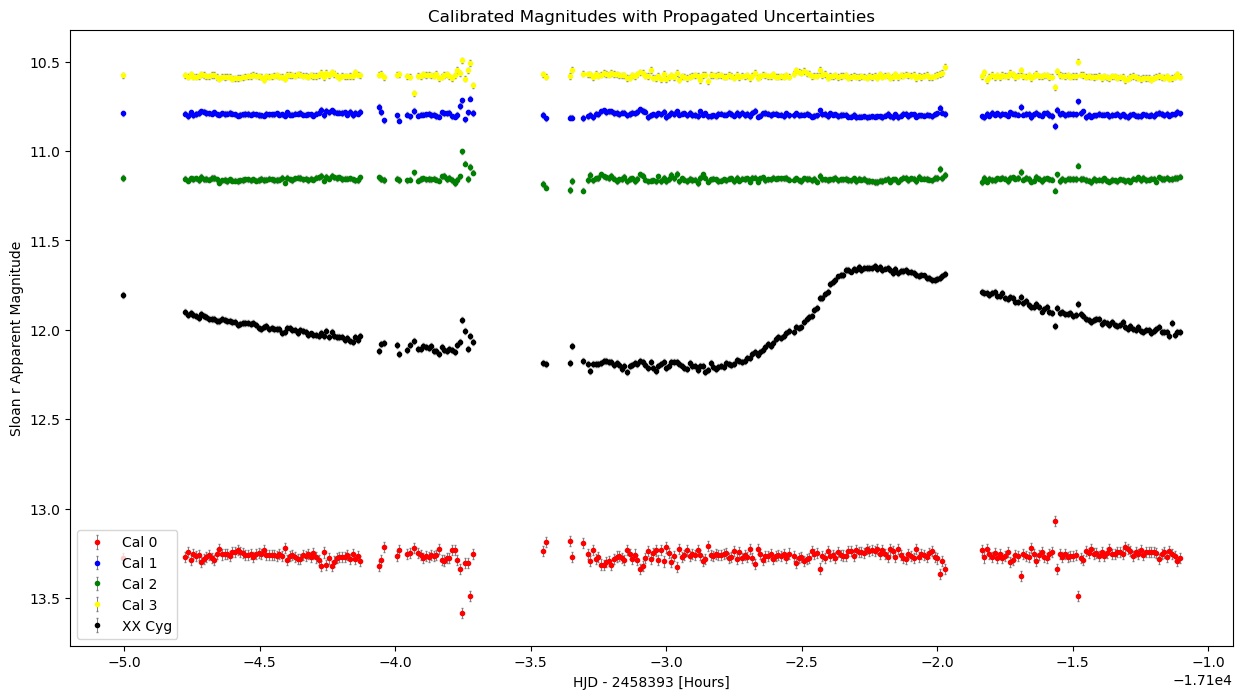

<Figure size 640x480 with 0 Axes>

In [108]:
plt.figure(figsize=(15, 8))
ax = plt.subplot()

offset = 2458393
ndates = len(obsDate)
xval = (obsDate - offset) * 24  # convert to hours for x-axis
xrange = [np.nanmin(xval), np.nanmax(xval)]

# ---- Calibrators ----
plt.errorbar(xval, rMag_cals[:, 0], yerr=cals_app_err[:, 0],
             fmt='.', mfc='red', mec='red', ecolor='grey', elinewidth=0.7, capsize=1, label='Cal 0')
plt.errorbar(xval, rMag_cals[:, 1], yerr=cals_app_err[:, 1],
             fmt='.', mfc='blue', mec='blue', ecolor='grey', elinewidth=0.7, capsize=1, label='Cal 1')
plt.errorbar(xval, rMag_cals[:, 2], yerr=cals_app_err[:, 2],
             fmt='.', mfc='green', mec='green', ecolor='grey', elinewidth=0.7, capsize=1, label='Cal 2')
plt.errorbar(xval, rMag_cals[:, 3], yerr=cals_app_err[:, 3],
             fmt='.', mfc='yellow', mec='yellow', ecolor='grey', elinewidth=0.7, capsize=1, label='Cal 3')

# ---- Variable (XX Cyg) ----
plt.errorbar(xval, rMag_xxCyg, yerr=xxCyg_app_err,
             fmt='.', mfc='black', mec='black', ecolor='grey', elinewidth=0.7, capsize=1, label='XX Cyg')

# ---- Labels and formatting ----
plt.xlabel('HJD - ' + str(offset) + ' [Hours]')
plt.ylabel('Sloan r Apparent Magnitude')
plt.title('Calibrated Magnitudes with Propagated Uncertainties')
plt.legend()
ax.invert_yaxis()  # small mag = bright star

plt.savefig('calibrated_magnitudes.pdf')
plt.show()

### 5.3 Period uncertainty (periodogram peak width)

In [111]:
import numpy as np
from astropy.timeseries import LombScargle

# Inputs: time in days, calibrated magnitudes and their propagated errors
time = (xval / 24.0).astype(float)   # days
mag = rMag_xxCyg.astype(float)
mag_err = xxCyg_app_err.astype(float)

# broad, oversampled search to get a clean period & arrays to work with
min_f, max_f = 0.1, 10.0   # cycles/day
frequency, power = LombScargle(time, mag, mag_err).autopower(
    minimum_frequency=min_f, maximum_frequency=max_f,
    samples_per_peak=200, nyquist_factor=10
)

# locate peak
imax = np.argmax(power)
f0 = frequency[imax]
P0 = 1.0 / f0

# estimate FWHM around the main peak
half = power[imax] / 2.0

# walk left to half max
iL = imax
while iL > 0 and power[iL] > half:
    iL -= 1
# walk right to half max
iR = imax
while iR < len(power)-1 and power[iR] > half:
    iR += 1

# linear interpolate for better half-max frequencies
def interp_x(i1, i2, y):
    x1, x2, y1, y2 = frequency[i1], frequency[i2], power[i1], power[i2]
    return x1 + (y - y1)*(x2 - x1)/(y2 - y1)

fL = interp_x(iL, iL+1, half)
fR = interp_x(iR-1, iR, half)
FWHM_f = fR - fL

# convert FWHM in frequency to sigma_f (Gaussian approx), then to sigma_P
sigma_f = FWHM_f / 2.355
sigma_P = (1.0 / f0**2) * sigma_f

print(f"Period ≈ {P0:.6f} ± {sigma_P:.6f} days  (from periodogram peak width)")

Period ≈ 0.127843 ± 0.048189 days  (from periodogram peak width)


## 6. Distance


In [ ]:
# Distance from the δ Scuti period–luminosity relation (McNamara 2011),
# using the period above and the mean calibrated magnitude of XX Cyg.
P, sigma_P = 0.1283, 0.0482        # days
m_r, sigma_m = 12.04, 0.05         # mean apparent Sloan r magnitude
VminusR, sigma_VR = 0.16, 0.05     # intrinsic colour (V - r)_0
A_r, sigma_A = 0.20, 0.05          # extinction in r
sigma_PL = 0.25                    # intrinsic scatter of the P–L relation

M_V = -1.83 - 3.65 * np.log10(P)
M_r = M_V - VminusR
d_pc = 10 ** ((m_r - M_r - A_r + 5) / 5)

# Propagate uncertainties through the distance modulus
sigma_MV = np.sqrt((3.65 * sigma_P / (P * np.log(10)))**2 + sigma_PL**2)
sigma_mu = np.sqrt(sigma_m**2 + sigma_MV**2 + sigma_VR**2 + sigma_A**2)
sigma_d = d_pc * np.log(10) / 5 * sigma_mu

print(f"M_r = {M_r:+.2f}")
print(f"Distance = {d_pc/1000:.2f} ± {sigma_d/1000:.2f} kpc   (Gaia DR3: 1.16 ± 0.02 kpc)")

M_r = +1.26
Distance = 1.30 ± 0.39 kpc   (Gaia DR3: 1.16 ± 0.02 kpc)
